<a href="https://colab.research.google.com/github/laboratoriodecodigos/Colab-Python/blob/main/video_raza_de_perro.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Esta IA adivina la raza de cualquier perro
**Laboratorio de Códigos** · ConvNeXt preentrenada en ImageNet (118 razas) + Grad-CAM

Sin entrenar nada: sube fotos de perros y obtén la raza (top 3 con porcentaje), qué tan seguro está de que es un perro y en qué parte de la foto se fijó.


In [ ]:
from google.colab import files
subidas = files.upload()            # puedes seleccionar varias fotos a la vez
FOTOS = list(subidas)
print(len(FOTOS), "fotos")

Saving yamabsm-halloween-7553022_1920.jpg to yamabsm-halloween-7553022_1920 (1).jpg
Saving pexels-pug-1834721_1920.jpg to pexels-pug-1834721_1920 (1).jpg
Saving maminounou-animal-7901464_1920.jpg to maminounou-animal-7901464_1920.jpg
Saving black17bg-english-bulldog-5422018_1920.jpg to black17bg-english-bulldog-5422018_1920.jpg
Saving anders_mejlvang-dog-6112872_1920.jpg to anders_mejlvang-dog-6112872_1920 (1).jpg
5 fotos


## 1. Modelo preentrenado

In [ ]:
import torch, torchvision, numpy as np
from torchvision import transforms as T
from PIL import Image

dispositivo = "cuda" if torch.cuda.is_available() else "cpu"
pesos = torchvision.models.ConvNeXt_Tiny_Weights.IMAGENET1K_V1
modelo = torchvision.models.convnext_tiny(weights=pesos).to(dispositivo).eval()
categorias = pesos.meta["categories"]

# En ImageNet, las clases 151 a 268 son razas de perro (118 razas)
RAZAS = list(range(151, 269))
print(f"{len(RAZAS)} razas, de '{categorias[151]}' a '{categorias[268]}'")

ESP = {  # nombres en español de las más comunes (las demás quedan en inglés)
    "Chihuahua": "Chihuahua", "Mexican hairless": "Xoloitzcuintle", "Labrador retriever": "Labrador",
    "golden retriever": "Golden retriever", "German shepherd": "Pastor alemán", "pug": "Pug",
    "Siberian husky": "Husky siberiano", "Pomeranian": "Pomerania", "French bulldog": "Bulldog francés",
    "beagle": "Beagle", "Rottweiler": "Rottweiler", "dalmatian": "Dálmata", "Border collie": "Border collie",
    "Yorkshire terrier": "Yorkshire", "Shih-Tzu": "Shih tzu", "Doberman": "Dóberman", "boxer": "Bóxer",
    "Great Dane": "Gran danés", "standard poodle": "Poodle", "miniature poodle": "Poodle miniatura",
    "toy poodle": "Poodle toy", "Maltese dog": "Maltés", "miniature schnauzer": "Schnauzer miniatura",
    "standard schnauzer": "Schnauzer", "giant schnauzer": "Schnauzer gigante", "cocker spaniel": "Cocker spaniel",
    "chow": "Chow chow", "Saint Bernard": "San Bernardo", "Pembroke": "Corgi", "Cardigan": "Corgi cardigan",
    "basset": "Basset hound", "bloodhound": "Sabueso", "Great Pyrenees": "Pirineo", "malamute": "Malamute",
    "Samoyed": "Samoyedo", "Bernese mountain dog": "Boyero de Berna", "Shetland sheepdog": "Pastor de Shetland",
    "collie": "Collie", "Old English sheepdog": "Pastor inglés", "Pekinese": "Pekinés", "Lhasa": "Lhasa apso",
    "papillon": "Papillón", "Weimaraner": "Weimaraner", "vizsla": "Vizsla", "whippet": "Whippet",
    "Italian greyhound": "Galgo italiano", "American Staffordshire terrier": "Pitbull / Amstaff",
    "Staffordshire bullterrier": "Staffordshire", "Boston bull": "Boston terrier", "Akita": "Akita",
    "Shiba": "Shiba inu", "Dandie Dinmont": "Dandie Dinmont", "Newfoundland": "Terranova",
}
nombre = lambda i: ESP.get(categorias[i], categorias[i])

recorte = T.Compose([T.Resize(256), T.CenterCrop(224)])
normaliza = T.Compose([T.ToTensor(), T.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])])

118 razas, de 'Chihuahua' a 'Mexican hairless'


## 2. Predicción + mapa de calor

In [ ]:
import cv2

# Grad-CAM sobre la última etapa convolucional de ConvNeXt
_act, _grad = {}, {}
capa = modelo.features[-1]
def _guardar(m, i, o):
    _act["a"] = o
    o.register_hook(lambda g: _grad.__setitem__("g", g))   # gradiente de esa misma salida
capa.register_forward_hook(_guardar)

def analizar(ruta, top=3):
    img = recorte(Image.open(ruta).convert("RGB"))
    x = normaliza(img).unsqueeze(0).to(dispositivo)
    modelo.zero_grad()
    logits = modelo(x)[0]
    p_todas = torch.softmax(logits, 0)
    es_perro = float(p_todas[RAZAS].sum())                 # ¿cuánto cree que es un perro?
    p_raza = torch.softmax(logits[RAZAS], 0)               # probabilidad solo entre razas
    mejores = torch.topk(p_raza, top)
    idx = RAZAS[int(mejores.indices[0])]
    logits[idx].backward()
    pesos_c = _grad["g"].mean(dim=(2, 3), keepdim=True)
    cam = torch.relu((pesos_c * _act["a"]).sum(1))[0].detach().cpu().numpy()
    cam = cv2.resize(cam / (cam.max() + 1e-8), img.size)
    calor = cv2.applyColorMap(np.uint8(255 * cam), cv2.COLORMAP_JET)[:, :, ::-1]
    mezcla = np.uint8(0.55 * np.array(img) + 0.45 * calor)
    razas = [(nombre(RAZAS[int(i)]), float(p)) for i, p in zip(mejores.indices, mejores.values)]
    return {"archivo": ruta, "es_perro": es_perro, "top": razas, "img": np.array(img), "calor": mezcla}

## 3. Resultados
- **es_perro_pct:** probabilidad total de que la foto sea un perro (si es baja, la raza no es confiable).
- **Top 3:** probabilidad solo entre las razas. Si el 1º y el 2º están cerca, probablemente es una mezcla.

                                   archivo  es_perro_pct           raza_1  prob_1_pct            raza_2  prob_2_pct          raza_3  prob_3_pct
    yamabsm-halloween-7553022_1920 (1).jpg          68.3           kelpie        65.7     Pastor alemán        10.2      schipperke         5.1
           pexels-pug-1834721_1920 (1).jpg          90.2              Pug        96.9      bull mastiff         0.4  Boston terrier         0.4
        maminounou-animal-7901464_1920.jpg           3.8 Golden retriever         2.4          Labrador         2.0         Sabueso         1.9
black17bg-english-bulldog-5422018_1920.jpg          83.6     bull mastiff        83.5             Bóxer         4.0 Bulldog francés         2.3
  anders_mejlvang-dog-6112872_1920 (1).jpg          90.3   Xoloitzcuintle        96.3 Pitbull / Amstaff         0.3   Staffordshire         0.3


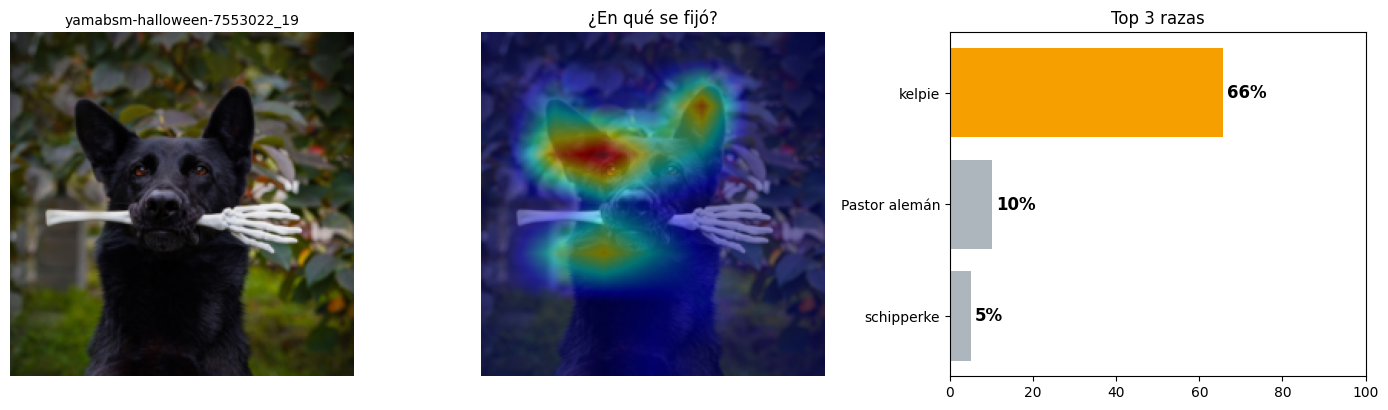

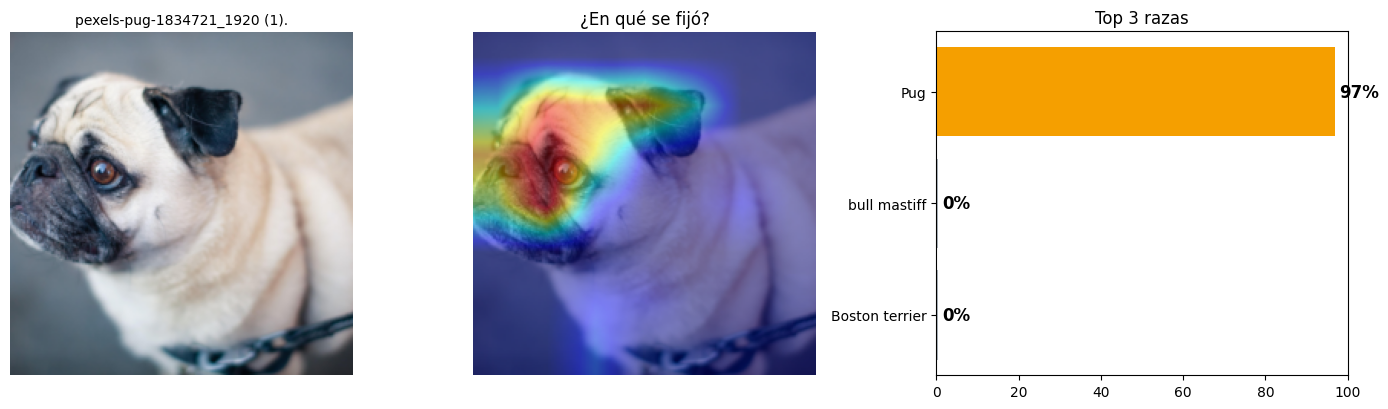

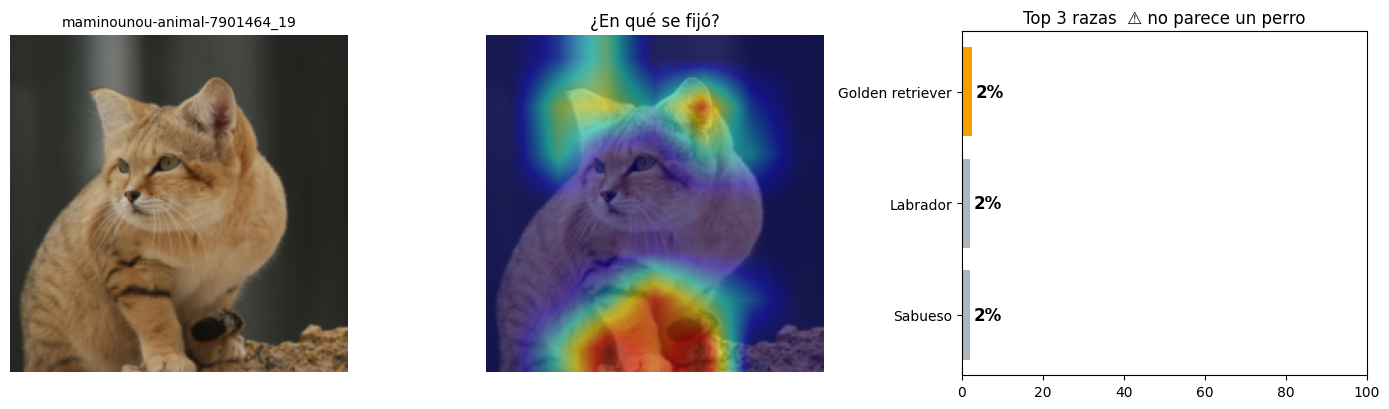

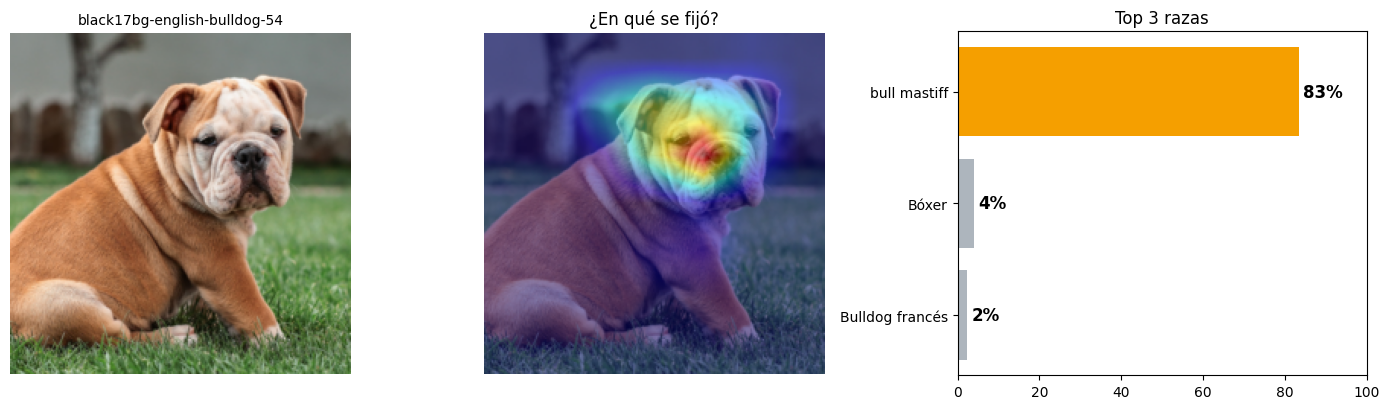

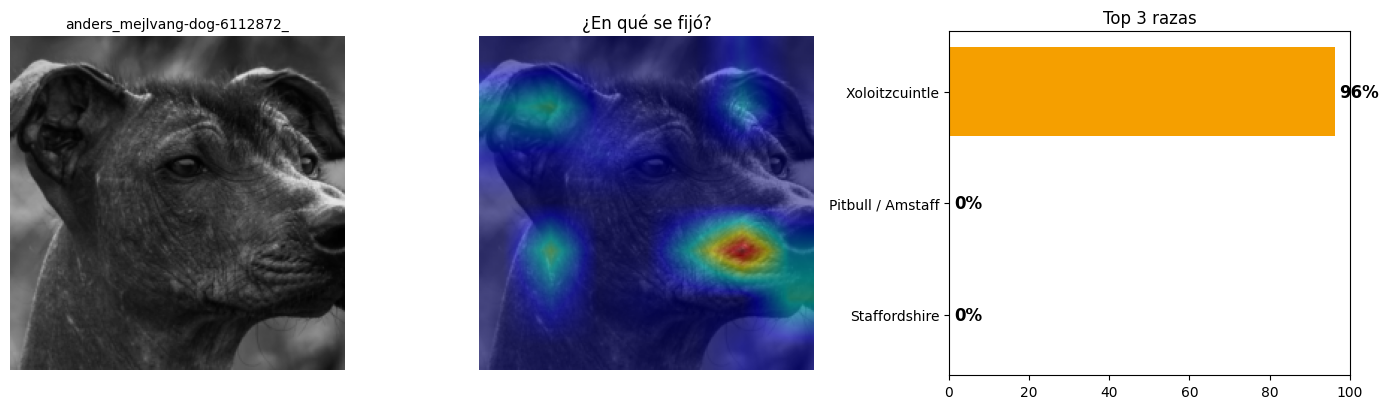

In [ ]:
import pandas as pd, matplotlib.pyplot as plt

resultados = [analizar(f) for f in FOTOS]
tabla = pd.DataFrame([{
    "archivo": r["archivo"],
    "es_perro_pct": round(r["es_perro"] * 100, 1),
    "raza_1": r["top"][0][0], "prob_1_pct": round(r["top"][0][1] * 100, 1),
    "raza_2": r["top"][1][0], "prob_2_pct": round(r["top"][1][1] * 100, 1),
    "raza_3": r["top"][2][0], "prob_3_pct": round(r["top"][2][1] * 100, 1),
} for r in resultados])
tabla.to_csv("razas_resultados.csv", index=False)
print(tabla.to_string(index=False))

for r in resultados:
    fig, ax = plt.subplots(1, 3, figsize=(14, 4.2), gridspec_kw={"width_ratios": [1, 1, 1.2]})
    ax[0].imshow(r["img"]); ax[0].set_title(r["archivo"][:28], fontsize=10)
    ax[1].imshow(r["calor"]); ax[1].set_title("¿En qué se fijó?", fontsize=12)
    nombres = [n for n, _ in r["top"]][::-1]; probs = [p * 100 for _, p in r["top"]][::-1]
    ax[2].barh(nombres, probs, color=["#adb5bd", "#adb5bd", "#f59f00"]); ax[2].set_xlim(0, 100)
    for i, p in enumerate(probs):
        ax[2].text(p + 1, i, f"{p:.0f}%", va="center", fontsize=12, fontweight="bold")
    aviso = "" if r["es_perro"] > 0.5 else "  ⚠️ no parece un perro"
    ax[2].set_title(f"Top 3 razas{aviso}", fontsize=12)
    ax[0].axis("off"); ax[1].axis("off")
    plt.tight_layout(); plt.show()

In [ ]:
files.download("razas_resultados.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**Ideas para el video:** prueba con un perro mestizo (¿qué mezcla ve?), con un xoloitzcuintle, o con un gato, un peluche o una persona para ver cómo reacciona `es_perro_pct`.